## Regresion lineal multiple California Housing

Vamos a implementar un modelo de regresión lineal múltiple para predecir el valor medio de las viviendas en distintas zonas de California, utilizando el dataset California Housing de scikit-learn.
Este ejemplo permite practicar un problema de regresión con más de 20.000 registros y ocho variables predictoras.

1. Objetivo del modelo
El dataset contiene información agregada por zona geográfica. La variable que queremos predecir es MedHouseVal, el valor medio de las viviendas expresado en centenas de miles de dólares.

Variable	Descripción
MedInc	Ingreso medio de los hogares de la zona
HouseAge	Antigüedad media de las viviendas
AveRooms	Cantidad media de habitaciones
AveBedrms	Cantidad media de dormitorios
Population	Población de la zona
AveOccup	Ocupación media por vivienda
Latitude	Latitud geográfica
Longitude	Longitud geográfica
MedHouseVal	Valor medio de las viviendas (objetivo)

Importante: no se predice el precio de una casa individual, sino el valor medio de las viviendas de una zona. Además, el objetivo tiene un límite superior en este dataset, por lo que no representa necesariamente el mercado inmobiliario actual.

Cantidad de registros: 20640
Cantidad de variables: 8

Primeros registros:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Estadísticas descriptivas:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000 

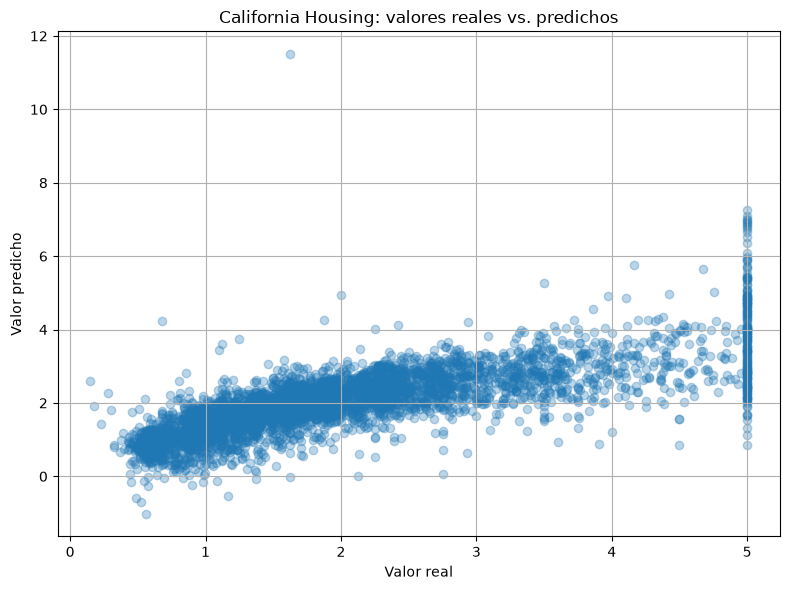


--- Predicción para una zona nueva ---
Valor estimado: 2.5217
Equivalente en USD: $252,173


: 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Cargar el dataset
housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target

print("Cantidad de registros:", X.shape[0])
print("Cantidad de variables:", X.shape[1])

print("\nPrimeros registros:")
print(X.head())

print("\nEstadísticas descriptivas:")
print(X.describe())

# 2. Dividir los datos
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nRegistros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

# 3. Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Realizar predicciones
y_pred = modelo.predict(X_test)

# 5. Evaluar el modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("\n--- Evaluación del modelo ---")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

# 6. Analizar los coeficientes
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

print("\nCoeficientes:")
print(coeficientes.sort_values(
    by="Coeficiente",
    ascending=False
))

print(f"\nIntercepto: {modelo.intercept_:.4f}")

# 7. Graficar valores reales vs. predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("California Housing: valores reales vs. predichos")
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Predecir para una vivienda/zona nueva
nueva_zona = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 25.0,
    "AveRooms": 5.0,
    "AveBedrms": 1.0,
    "Population": 1000.0,
    "AveOccup": 3.0,
    "Latitude": 34.0,
    "Longitude": -118.0
}])

prediccion = modelo.predict(nueva_zona)[0]

# La variable objetivo está expresada en unidades de
# 100.000 dólares.
valor_usd = prediccion * 100_000

print("\n--- Predicción para una zona nueva ---")
print(f"Valor estimado: {prediccion:.4f}")
print(f"Equivalente en USD: ${valor_usd:,.0f}")
